[课程目录](../../README.md#4-按主题学习-notebook) · [环境部署](../../README.md#1-配置-python-环境)

用 H、受控旋转和 SWAP 构建三比特 QFT。

本篇可独立从上到下运行，请选择仓库 `.venv` 对应的内核。

# 量子傅里叶变换

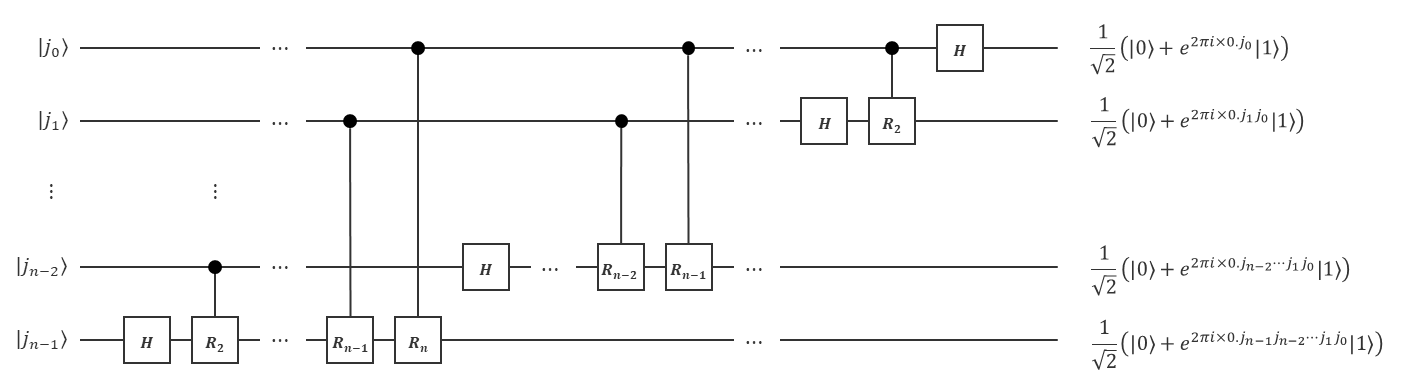

## 例1
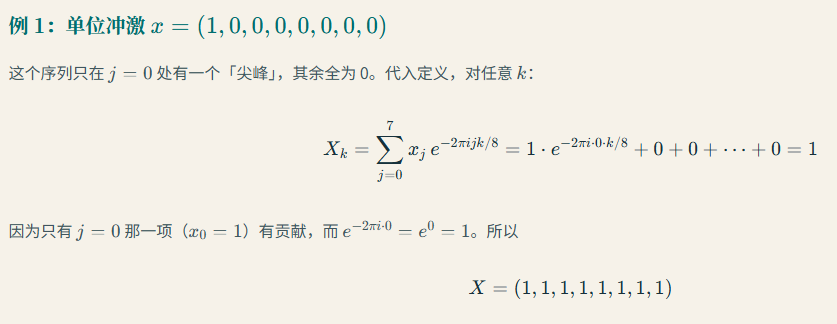

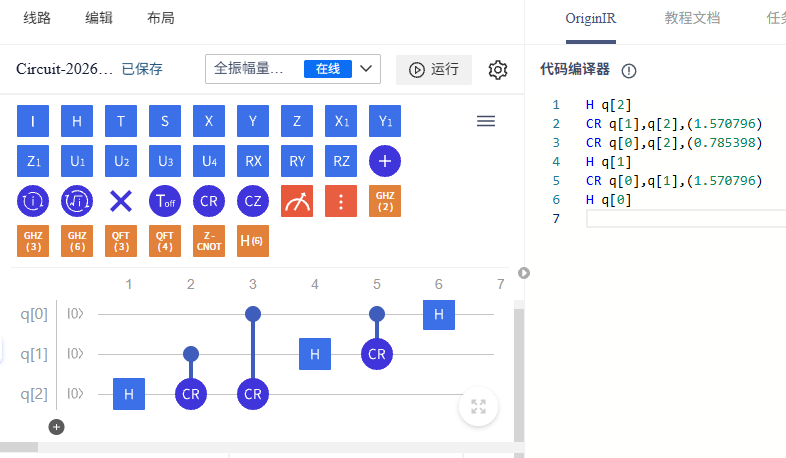

In [1]:
from numpy import pi
from pyqpanda3.core import H, CR, QCircuit, SWAP, draw_qprog
from pyqpanda3.quantum_info import StateVector

In [2]:
qft_q3 = QCircuit(3)
qft_q3 << H(2) << CR(1, 2, pi/2) << CR(0, 2, pi/4)
qft_q3 << H(1) << CR(0, 1, pi/2)
qft_q3 << H(0)

qft_q3 << SWAP(0, 2)

print(draw_qprog(qft_q3, param_show=True))


                                                                 ┌─┐   
q_0:  |0>──── ──────────────── ────────*─────── ────────*─────── ┤H├ X 
                                       │┌─┐     ┌───────┴──────┐ └─┘ │ 
q_1:  |0>──── ────────*─────── ────────┼┤H├──── ┤CP(1.57079633)├ ─── ┼ 
          ┌─┐ ┌───────┴──────┐ ┌───────┴┴─┴───┐ └──────────────┘     │ 
q_2:  |0>─┤H├ ┤CP(1.57079633)├ ┤CP(0.78539816)├ ──────────────── ─── X 
          └─┘ └──────────────┘ └──────────────┘                        
 c :   / ═════════════════════════════════════════════════════════════
                                                                      




In [3]:
init_state = StateVector(3) # |000\rangle
final_state = init_state.evolve(qft_q3)
print(final_state)

[0.35355339+0.j 0.35355339+0.j 0.35355339+0.j 0.35355339+0.j
 0.35355339+0.j 0.35355339+0.j 0.35355339+0.j 0.35355339+0.j]


## 图像展示

保留前面的文本结果；下面补充图像形式的线路或本次运行结果。

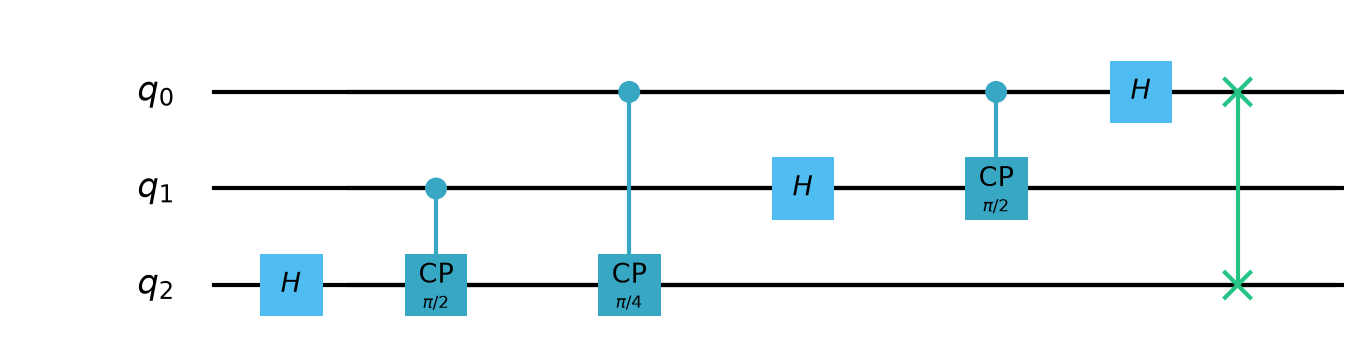

In [4]:
from pathlib import Path
from IPython.display import Image, display
import pyqpanda3.visualization

repo_root = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file())
figure_dir = repo_root / ".tmp/notebook-figures/day1"
figure_dir.mkdir(parents=True, exist_ok=True)
image_path = figure_dir / "06_quantum_fourier_transform.png"
qft_q3.draw("pic", filename=str(image_path), with_gate_params=True)
display(Image(filename=str(image_path)))


## 附录：从傅里叶定义推导 QFT，再用 Python 核对

阅读顺序：**定义与位序 → 酉性 → 张量积分解 → 门线路 → 相位与干涉实验**。只需复数指数、矩阵乘法和张量积的基础；$i^2=-1$，$\langle u|v\rangle$ 是内积，$U^\dagger$ 表示共轭转置。以下推导按本 Notebook 的位序重新组织，代码均可在本地运行。

### A.1 定义：变换的是振幅，不是测量后的数字列表

设 $n$ 个量子比特，$N=2^n$。固定计算基顺序

$$
|x\rangle=|x_{n-1}\cdots x_1x_0\rangle,
\qquad x=\sum_{r=0}^{n-1}x_r2^r.
$$

这里 $q_0$ 为最低位；三比特的状态向量按 $|000\rangle,|001\rangle,\ldots,|111\rangle$ 排列。若按 $q_r\to c_r$ 测量，返回字符串读作 $c_{n-1}\cdots c_0$，此时才与量子比特的同编号位一致。

采用**正指数**约定：

$$
F_N|x\rangle=\frac1{\sqrt N}\sum_{k=0}^{N-1}e^{2\pi i xk/N}|k\rangle,
\qquad (F_N)_{k,x}=\frac{e^{2\pi i xk/N}}{\sqrt N}.
$$

由线性性，对归一化输入 $|\psi\rangle=\sum_xa_x|x\rangle$，输出振幅为

$$
b_k=\frac1{\sqrt N}\sum_{x=0}^{N-1}a_xe^{2\pi i xk/N},
\qquad \Pr(k)=|b_k|^2.
$$

QFT 把一个量子态变成另一个量子态；测量只给出一个样本，不能一次读出全部复振幅。NumPy 默认 `fft` 用负指数，因此本约定对应 `np.fft.ifft(a) * np.sqrt(N)`，不能直接拿 `fft(a)` 比较。

### A.2 为什么这个矩阵可以由量子门实现

对任意 $x,y\in\{0,\ldots,N-1\}$，

$$
(F_N^\dagger F_N)_{x,y}
=\frac1N\sum_{k=0}^{N-1}e^{2\pi i(y-x)k/N}
=\begin{cases}1,&x=y,\\0,&x\ne y.\end{cases}
$$

第二种情况令 $z=e^{2\pi i(y-x)/N}$，则 $z\ne1$、$z^N=1$，等比级数为 $(1-z^N)/(1-z)=0$。所以 $F_N^\dagger F_N=I$：它保持归一化，逆变换就是 $F_N^\dagger$，即把指数的正号改成负号。$n=1$ 时 $F_2=H$。


### A.3 从求和到张量积：受控相位从哪里来

把输出索引写成 $k=k_{n-1}\cdots k_0$。由于

$$
\frac{k}{2^n}=\sum_{m=1}^{n}\frac{k_{n-m}}{2^m},
\qquad e^{2\pi ixk/2^n}=\prod_{m=1}^{n}e^{2\pi ixk_{n-m}/2^m},
$$

逐位展开求和，就得到按 $q_{n-1},\ldots,q_0$ 排列的张量积：

$$
\begin{aligned}
F_N|x\rangle
&=\frac1{2^{n/2}}\sum_{k_{n-1},\ldots,k_0\in\{0,1\}}
\left(\prod_{m=1}^{n}e^{2\pi ixk_{n-m}/2^m}\right)|k_{n-1}\cdots k_0\rangle\\
&=\bigotimes_{m=1}^{n}\frac{|0\rangle+e^{2\pi ix/2^m}|1\rangle}{\sqrt2}\\
&=\frac{|0\rangle+e^{2\pi i\,0.x_0}|1\rangle}{\sqrt2}
\otimes\frac{|0\rangle+e^{2\pi i\,0.x_1x_0}|1\rangle}{\sqrt2}
\otimes\cdots\otimes
\frac{|0\rangle+e^{2\pi i\,0.x_{n-1}\cdots x_0}|1\rangle}{\sqrt2}.
\end{aligned}
$$

其中 $0.x_{m-1}\cdots x_0=\sum_{r=0}^{m-1}x_r2^{r-m}$ 是**二进制小数**。整数部分不影响 $e^{2\pi i t}$，所以可以把 $x/2^m$ 换成这个小数。这个乘积形式针对计算基输入；任意输入应先线性展开，输出未必仍是乘积态。

教材定义 $R_m=\operatorname{diag}(1,e^{2\pi i/2^m})$。仓库的 `CR(control, target, angle)` 是受控相位门，矩阵为 $\operatorname{diag}(1,1,1,e^{i\,angle})$，并非受控 $R_Y$ 或受控 $R_Z$。

三比特输入 $|x_2x_1x_0\rangle$ 时，原线路逐步得到：

| 原代码操作 | 相应线上 $\lvert1\rangle$ 的相位因子 |
|---|---|
| `H(2)` | $e^{2\pi i x_2/2}$ |
| 再做 `CR(1, 2, pi/2)` | $e^{2\pi i(x_2/2+x_1/4)}$ |
| 再做 `CR(0, 2, pi/4)` | $e^{2\pi i\,0.x_2x_1x_0}$ |
| `H(1)` 与 `CR(0, 1, pi/2)` | $q_1$ 上为 $e^{2\pi i\,0.x_1x_0}$ |
| `H(0)` | $q_0$ 上为 $e^{2\pi i\,0.x_0}$ |

这些相位因子都对应归一化的 $(|0\rangle+e^{i\phi}|1\rangle)/\sqrt2$。此时各线的因子顺序与上面的 QFT 定义相反，末尾 `SWAP(0, 2)` 才把它们放回规定的位置。省略交换得到的是 $B F_N$，其中 $B$ 反转输出索引的二进制位，不能在后续运算中无条件视为 $F_N$。

下面把原线路推广到 $n$ 比特，并用全部计算基逐列核对矩阵。它比只验证 $|000\rangle$ 更严格：零输入无法区分相位符号或输出位反转。


In [5]:
import numpy as np

def qft_circuit(n, *, swaps=True):
    circuit = QCircuit(n)
    for target in range(n - 1, -1, -1):
        circuit << H(target)
        for control in range(target - 1, -1, -1):
            angle = 2 * np.pi / 2 ** (target - control + 1)
            circuit << CR(control, target, angle)
    if swaps:
        for low in range(n // 2):
            circuit << SWAP(low, n - 1 - low)
    return circuit

def circuit_matrix(circuit, n):
    basis = np.eye(2**n, dtype=complex)
    return np.column_stack([
        np.asarray(StateVector(column.tolist()).evolve(circuit).ndarray()).reshape(-1)
        for column in basis.T
    ])

qft_n = 3
qft_N = 2**qft_n
indices = np.arange(qft_N)
F_reference = np.exp(2j * np.pi * np.outer(indices, indices) / qft_N) / np.sqrt(qft_N)
F_circuit = circuit_matrix(qft_circuit(qft_n), qft_n)
F_original = circuit_matrix(qft_q3, qft_n)
bit_reversal = np.array([int(format(k, f"0{qft_n}b")[::-1], 2) for k in indices])
F_without_swaps = circuit_matrix(qft_circuit(qft_n, swaps=False), qft_n)

np.testing.assert_allclose(F_circuit, F_reference, atol=1e-12)
np.testing.assert_allclose(F_original, F_reference, atol=1e-12)
np.testing.assert_allclose(F_without_swaps, F_reference[bit_reversal], atol=1e-12)
np.testing.assert_allclose(F_circuit.conj().T @ F_circuit, np.eye(qft_N), atol=1e-12)
print(f"全部 {qft_N} 个基态核对通过，最大矩阵误差：{np.max(np.abs(F_circuit-F_reference)):.2e}")


全部 8 个基态核对通过，最大矩阵误差：1.46e-15


### A.4 相位不能只靠直方图判断：输入 $|001\rangle$

令 $\omega=e^{2\pi i/8}$，则 $F_8|1\rangle=8^{-1/2}\sum_{k=0}^7\omega^k|k\rangle$。各项概率全为 $1/8$，但相邻振幅的相位差为 $\pi/4$。原来的零输入示例则相位全部为零。

以下直接读取的是**经典模拟器提供的状态向量**，不是声称真实硬件能一次读出全部振幅。把 QFT 的输出送入 `.dagger()` 构造的逆线路，应恢复输入；这同时检验相位和位序。


In [6]:
qft_input = np.zeros(qft_N, dtype=complex)
qft_input[1] = 1  # |001>，不是 |100>
qft_output = np.asarray(StateVector(qft_input.tolist()).evolve(qft_circuit(qft_n)).ndarray()).reshape(-1)
qft_recovered = np.asarray(StateVector(qft_output.tolist()).evolve(qft_circuit(qft_n).dagger()).ndarray()).reshape(-1)
np.testing.assert_allclose(qft_recovered, qft_input, atol=1e-12)
np.testing.assert_allclose(qft_output, np.fft.ifft(qft_input) * np.sqrt(qft_N), atol=1e-12)
print("输出位串    振幅                      概率")
for k, amplitude in enumerate(qft_output):
    print(f"{k:03b}        {amplitude.real:+.6f}{amplitude.imag:+.6f}j     {abs(amplitude)**2:.6f}")
print("逆变换恢复 |001>：", np.allclose(qft_recovered, qft_input))


输出位串    振幅                      概率
000        +0.353553+0.000000j     0.125000
001        +0.250000+0.250000j     0.125000
010        +0.000000+0.353553j     0.125000
011        -0.250000+0.250000j     0.125000
100        -0.353553+0.000000j     0.125000
101        -0.250000-0.250000j     0.125000
110        -0.000000-0.353553j     0.125000
111        +0.250000-0.250000j     0.125000
逆变换恢复 |001>： True


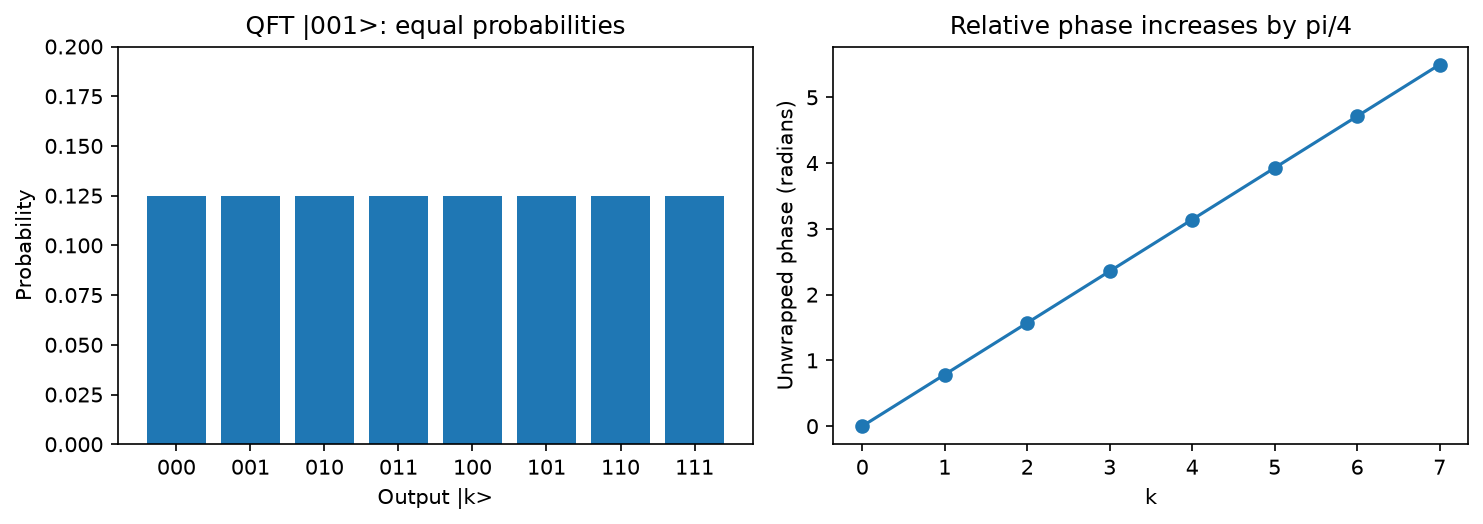

In [7]:
from io import BytesIO
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
labels = [format(k, "03b") for k in indices]
axes[0].bar(labels, np.abs(qft_output)**2)
axes[0].set(xlabel="Output |k>", ylabel="Probability", ylim=(0, 0.2), title="QFT |001>: equal probabilities")
axes[1].plot(indices, np.unwrap(np.angle(qft_output)), "o-")
axes[1].set(xlabel="k", ylabel="Unwrapped phase (radians)", title="Relative phase increases by pi/4", xticks=indices)
fig.tight_layout()
buffer = BytesIO()
fig.savefig(buffer, format="png", dpi=150, bbox_inches="tight")
plt.close(fig)
display(Image(data=buffer.getvalue()))


### A.5 干涉如何把相位结构变成可见概率

考虑 $|\psi\rangle=(|0\rangle+|4\rangle)/\sqrt2$，则

$$
\langle k|F_8|\psi\rangle=\frac{1+e^{\pi i k}}4
=\begin{cases}1/2,&k\text{ 为偶数},\\0,&k\text{ 为奇数}.\end{cases}
$$

因此只可能测到 $000,010,100,110$，概率各 $1/4$。这是相干振幅相加再取模平方，不能把两个均匀概率分布直接相加。逆 QFT 也常用来把相位估计中的相位梯度转成二进制读数；完整相位估计还需要额外寄存器和受控幂操作，本例不包含这些步骤。


In [8]:
periodic_input = np.zeros(8, dtype=complex)
periodic_input[[0, 4]] = 1 / np.sqrt(2)
periodic_output = np.asarray(StateVector(periodic_input.tolist()).evolve(qft_circuit(3)).ndarray()).reshape(-1)
periodic_probabilities = np.abs(periodic_output)**2
np.testing.assert_allclose(periodic_probabilities, [0.25, 0, 0.25, 0, 0.25, 0, 0.25, 0], atol=1e-12)
print("干涉后的概率：", {format(k, "03b"): round(float(p), 6) for k, p in enumerate(periodic_probabilities)})


干涉后的概率： {'000': 0.25, '001': 0.0, '010': 0.25, '011': 0.0, '100': 0.25, '101': 0.0, '110': 0.25, '111': 0.0}


### A.6 复杂度、练习与资料扩展

精确线路使用 $n$ 个 H、$n(n-1)/2$ 个受控相位和 $\lfloor n/2\rfloor$ 个 SWAP，即 $O(n^2)$ 个这些门。它作用于 $2^n$ 维**量子态**；经典 FFT 则读写整个长度为 $N$ 的经典数组，复杂度为 $O(N\log N)$。输入制备和完整输出读取的成本不同，不能据此宣称 QFT 能免费替代任意经典数据处理中的 FFT。本附录逐列建立矩阵也需指数规模，仅用于小线路核对。

练习：把输入改为 $|011\rangle$，先预测振幅比 $b_{k+1}/b_k=e^{2\pi i3/8}$，再运行；去掉 SWAP 时，对照 `bit_reversal` 检查振幅的具体位置。对任意归一化复向量，验证 $F_N^\dagger F_N|\psi\rangle=|\psi\rangle$，并说明为什么“测量得到均匀分布”不足以证明线路正确。

**教材定位（独立整理与推导，不复制教材页面）：**

- Nielsen、Chuang，*Quantum Computation and Quantum Information*, 10th Anniversary Edition (2010)，§5.1，印刷页 217–220，本地英文 PDF 第 251–254 页；定义、乘积分解与末尾换位见式 (5.2)、(5.4) 和图 5.1。
- 《量子计算与量子信息：10 周年版》（本地 2022 中文版），§5.1，印刷页 185–188，PDF 第 219–222 页；可对照相同式号阅读。教材 $j_1$ 是最高位，此处对应 $x_{n-1}$。
- 郭国平、窦猛汉、陈昭昀，《QPanda 量子计算编程》(2024)，§3.2，印刷页 37–40，PDF 第 49–52 页。其代码使用旧 `pyqpanda`；此处保留本仓库 `pyqpanda3` API，并显式核对位序和交换。
- 本地课件 `pyqpanda3培训-day1-261017.pdf` 第 191–196 页可与本篇原有图示对读。

本地教材位于 `docs/pdf/`，已被 Git 忽略；上述页码供持有教材者定位，附录本身不依赖 PDF 文件即可学习和运行。
